# 中文详解版 · 使用说明

这是 `homework-practice-01.ipynb` 的**中文讲解版**：作业原文全部译成中文，每一段代码后面附一段"代码讲解"，
每一道题后面给"讲解与答案"。所有输出（表格、数字、图表）都是真实跑出来的结果，不是示意图。

## 怎么读这一份

- **正文**：作业的原任务与问题（已翻译）。
- **代码讲解**（以 `>` 引用块呈现）：紧跟在代码格下方，讲这段代码在做什么、用到的函数是什么、为什么要这么写。
- **讲解与答案**：跟在问题下方，先讲直觉和原因，再给结论和数字。

## 建议的学习顺序

1. 先看**第 0 部分**，搞清楚数据长什么样、要回答什么问题。
2. **第 1 部分**是主体：13 个表格题，练的都是 pandas 的"基本动作"——读表、清空值、换类型、分组、排序、筛选。重点理解三个东西：`groupby`（按谁分组）、`apply`（对每个格子做什么）、"一行"和"一张订单"的区别。
3. **第 2 部分**是画图：直方图、折线、柱状、散点各画一张。重点理解"每种图回答什么问题"。

## 一条主线

整份作业其实只在做一件事：**把 4622 行小票整理成一张能算数的表，然后回答 13 个问题，最后画成 4 张图。**

| 阶段 | 你手里有什么 | 关键动作 |
|---|---|---|
| 读入 | 4622 行 × 5 列的原始表 | `read_csv` |
| 清洗 | 有 1246 个空值的表 | `isna` / `fillna` |
| 换算 | 价格还是文字 "$2.39 " | `apply` 去符号、转数字 |
| 统计 | 每一行都有了单价 | `groupby` 汇总、排序、筛选 |
| 可视化 | 每一单都有金额、有日期 | `hist` / `plot` / `bar` / `scatter` |

## 答案速查

| 题 | 问题 | 答案 |
|---|---|---|
| 1 | 表长什么样 | 4622 行 × 5 列：订单号、数量、商品名、配料、行总价 |
| 2 | 多少订单 / 多少种商品 | 1834 单 / 50 种 |
| 3 | 哪里有缺失 | 只有 `choice_description`，1246 个空 |
| 4 | 价格统计 | 均价 7.46，最低 1.09，最高 44.25 |
| 5 | 最便宜 / 最贵的 5 种商品 | 便宜：1.09 / 1.25 / 1.43 / 1.69 / 2.15；贵：沙拉碗约 11 |
| 6 | 买超过 1 个 Chicken Bowl 的次数 | 33 次 |
| 7 | 平均订单金额 / 平均件数 | $18.81 / 2.71 件 |
| 8 | 只买 1 件的订单数 | 56 单 |
| 9 | 最受欢迎的商品 | Chicken Bowl，726 次 |
| 10 | Burrito 种类 / 最常买 / 最贵 | 6 种 / Chicken Burrito / Steak Burrito |
| 11 | 有商品占整单 40% 以上的订单 | 1624 单 |
| 12 | Diet Coke 涨价后的增幅 | +8.00% |
| 13 | 新表存盘 | 已保存为 `random_matrix.csv` |


# 机器学习

## 实践作业 1：用 pandas 处理表格数据、用 matplotlib 画图


### 关于本作业

这次作业分两部分：**用 pandas 处理表格数据**，以及**用 matplotlib（seaborn、plotly）做可视化**。每部分都有若干小题，按分值给分，建议按题号顺序做——前面的题会把数据清洗好，后面的题直接用。

### 评分与扣分

每个任务后面括号里标了分值，总分的上限是 **10 分**（第 1 部分 6 分 + 第 2 部分 4 分）。

超过截止时间就不能交了。如果因为错误被扣了部分分，是否允许你补交，由评审在回复邮件里说明。

作业必须独立完成。"雷同"的作业会被视为抄袭，所有相关同学（包括被抄的人）该次作业得 0 分。如果你在开源代码里找到了某个任务的答案（或一部分），必须在这份作业末尾单独列一节给出链接——很可能不止你一个人找到，写上链接才能排除抄袭嫌疑。

### 提交格式

作业通过 EDUFPMI 门户的作业区提交。

为了方便评阅，请自己算一下你理论上能拿多少分，写在下面。

评分：10。


## 0. 介绍

我们现在在 Jupyter 笔记本（notebook）里。它是写代码、做实验、看数据、画图的好地方，但不是用来写生产代码的。

笔记本由一个个**单元格**组成，每个单元格要么是**代码格**，要么是**文本格**（支持 Markdown 排版和 LaTeX 公式）。

- 要编辑单元格，先按 **Enter** 进入**编辑模式**（边框变绿）。要切换单元格，先按 **Esc** 回到**命令模式**（边框变蓝）。
- 命令模式下按 **y** 把单元格设成代码格，按 **m** 设成文本格（Markdown），按 **r** 设成原始文本格。
- 写完按 **Shift + Enter** 运行：代码格会执行代码，文本格会渲染成排版好的文字。


In [1]:
#cell with code, when executed, output will appear
2 + 2

4

> **代码讲解**
>
> - `2 + 2` 是一个表达式。Jupyter 会把单元格里**最后一个表达式的值**自动显示出来——所以这格没有 `print` 也输出了 `4`。
> - 这是 notebook 和普通脚本最大的不同：随手写一句就能立刻看到结果，特别适合"试试看"。

下面演示文本格能做什么。这一格就是 Markdown（一种用纯文本写排版的标记语言）：

0. 写有序列表
1. # 写各种级别的标题
### 不同级别的标题
2. 强调 *重点*、**加粗**、~~删除线~~
3. 加链接：[给 pandas 文档](https://pandas.pydata.org/docs/)

* 也可以写无序列表

还可以插入 LaTeX 公式（渲染出来是一颗心）：

$$
\left\{
\begin{array}{ll}
x = 16 \sin^3 (t) \\
y = 13 \cos (t) - 5 \cos (2t) - 2 \cos (3t) - \cos (4t) \\
t \in [0, 2 \pi]
\end{array}
\right.
$$

> 另外，文本格里也能直接插图：`<img src="图片网址" style="width: 400px">`。


In [2]:
# A code cell of our own
print('My first cell: 2 ** 10 =', 2 ** 10)


My first cell: 2 ** 10 = 1024


> **代码讲解**：`print(...)` 把内容打印到输出里。`2 ** 10` 是 2 的 10 次方（Python 里用 `**` 表示乘方，不是 `^`）。这格只是演示"自己新建一个代码格"。


## 1. 表格数据与 Pandas

pandas 是 Python 里处理表格数据最常用的库。核心对象叫 **DataFrame**——你可以直接把它理解成"Python 版的 Excel 表格"：有行号（索引）、有列名、每列有自己的类型。DataFrame 可以读文件得到，也可以手动构造。

这部分要回答的 13 个问题都不难，难的是**熟悉 pandas 的"动词"**。下面这张小抄先混个眼熟，遇到不会的再回来查：

| 想干嘛 | 写法 | 一句话 |
|---|---|---|
| 读 CSV | `pd.read_csv('data.csv')` | 文件 → 表格 |
| 看前 / 后几行 | `df.head()` / `df.tail(10)` | 快速瞄一眼 |
| 看结构 | `df.shape`、`df.columns`、`df.dtypes` | 几行几列、列名、类型 |
| 数缺失 | `df.isna().sum()` | 每列几个空 |
| 填空 | `df.fillna(值)` | 空值 → 指定值 |
| 逐元素变换 | `df['列'].apply(函数)` | 对每个格子做同一件事 |
| 去重 | `df.drop_duplicates()` | 留下不重复的行 |
| 排序 | `df.sort_values('列')` | 按某列排 |
| 分组统计 | `df.groupby('列').agg(...)` | 按某列分堆、每堆汇总 |
| 汇总贴回每行 | `df.groupby('列')['列2'].transform('sum')` | 每组的总和，原样贴回组内每一行 |
| 数出现次数 | `df['列'].value_counts()` | 每种值出现几次 |
| 数不同值个数 | `df['列'].nunique()` | 有几个不重复的值 |
| 按条件取子集 | `df[df['列'] > 0]` | 只留下满足条件的行 |


In [3]:
# import almost all we need
import pandas as pd
import numpy as np


> **代码讲解**
>
> - `import pandas as pd`：导入 pandas，并约定简写成 `pd`。
> - `import numpy as np`：numpy 负责数值计算（数组、随机数），第 13 题造随机矩阵会用到。
>
> （原模板写的是 `%pylab inline`——那是老式写法，会把一大堆库一股脑塞进命名空间，现在已经弃用。我们改成明确地 `import`，更干净。）

### 数据从哪来

数据可以[从这里下载](https://www.dropbox.com/s/5qq94wzmbw4e54r/data.csv?dl=0)（Dropbox 链接，文件叫 `data.csv`）。下载后放在**这个 notebook 的同一个目录**里，下面的 `pd.read_csv('data.csv')` 才能读到。

> 小提示：如果 Jupyter 的"当前目录"不是 notebook 所在目录，可以 `import os; os.getcwd()` 看一眼。


### 1. [0.5 分] 打开表格文件（注意它的格式），打印最后 10 行。

看看数据，说说它是什么、有多少行、有哪些列。


In [4]:
df = pd.read_csv('data.csv')
df.tail(10)


      order_id  ...  item_price
4612      1831  ...      $9.25 
4613      1831  ...      $2.15 
4614      1831  ...      $1.50 
4615      1832  ...      $8.75 
4616      1832  ...      $4.45 
4617      1833  ...     $11.75 
4618      1833  ...     $11.75 
4619      1834  ...     $11.25 
4620      1834  ...      $8.75 
4621      1834  ...      $8.75 

[10 rows x 5 columns]

> **代码讲解**
>
> - `pd.read_csv('data.csv')`：读 CSV 文件，返回一个 DataFrame，存进变量 `df`。之后所有操作都在 `df` 上做。
> - `df.tail(10)`：看**最后** 10 行（`head()` 看前 5 行）。
> - 最后一行的 `df.tail(10)` 是表达式，所以 Jupyter 会把整张表显示出来——这就是不需要 `print` 的原因。

**讲解与答案**

**这数据是什么。** 一张"餐厅收银小票"的明细表：每一行 = 某张订单里的一种商品（连同数量、配料、这一行的钱）。**4622 行 × 5 列**。

- `order_id`：订单号（小票号）。同一个号的多行，属于同一张单。
- `quantity`：这一行买了几份。
- `item_name`：商品名（如 Chicken Bowl 鸡肉碗）。
- `choice_description`：选的配料，方括号括起来；没有配料的商品（薯片、饮料）这里是空的。
- `item_price`：**这一行一共花了多少钱**（注意：数量已经乘进去了）。

**怎么读 `tail(10)` 的输出。** 最后几行是订单 1831–1834 的小票，比如 1831 号单是 Carnitas Bowl $9.25 + Chips $2.15 + Bottled Water $1.50。这种"一行一行商品"的结构，就是后面所有统计的基础。


### 2. [0.25 分] 回答两个问题：

1. 样本里一共有多少张订单？
2. 一共买过多少种不同的商品？（看 `item_name`）


In [5]:
n_orders = df['order_id'].nunique()
n_items = df['item_name'].nunique()
print('Orders in the sample:', n_orders)
print('Unique product categories (item_name):', n_items)


Orders in the sample: 1834
Unique product categories (item_name): 50


> **代码讲解**
>
> - `df['order_id'].nunique()`：`order_id` 列一共 4622 个值，但很多行属于同一张单。`nunique()` 数的是"不重复的值有几个"，所以得到订单数。
> - `df['item_name'].nunique()`：同理，数商品名有几种。
> - `print` 把标签和值一起打出来，方便对照。

**讲解与答案**

- **1834 张订单**：4622 行数据，平均每单 2.52 行商品。
- **50 种商品**：从饮料、小吃到各种碗和卷饼。

一个小规律：后面凡是"按订单算"的题（第 7、8、11 题），都要先 `groupby('order_id')`，因为表的一行不是一单。


### 3. [0.25 分] 数据里有没有空缺（缺失值、NaN）？在哪些列里？


In [6]:
df.isna().sum()


order_id                 0
quantity                 0
item_name                0
choice_description    1246
item_price               0
dtype: int64

> **代码讲解**
>
> - `df.isna()`：把每个格子变成"是不是空"（True / False）。
> - `.sum()`：对每列数 True 的个数（True 当 1 加）。
> - 输出里 `choice_description 1246` 表示这一列有 1246 个空，其余列都是 0。

**讲解与答案**

**只有 `choice_description` 一列有空**，共 **1246 个**。

**为什么空？** 因为薯片、饮料、瓶装水这类商品没有配料可选，小票系统就不填这一栏。所以这里的空缺**不是数据错误**，而是"这个商品本来就没有这一项"。


填空：文字列填**空字符串**，数字列填 **0**。


In [7]:
# Empty string for string columns, zero for numeric columns
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(0)
    else:
        df[col] = df[col].fillna('')
df.isna().sum()


order_id              0
quantity              0
item_name             0
choice_description    0
item_price            0
dtype: int64

> **代码讲解**
>
> - 循环遍历所有列，按类型决定填什么。
> - `pd.api.types.is_numeric_dtype(列)`：判断这一列是不是数字类型。是 → 填 `0`；不是（文字）→ 填 `''`（空字符串）。
> - `df[col].fillna(值)`：把所有空值替换成指定值。
> - 最后再 `isna().sum()` 一次——输出全 0 才算真正填完，这是"验证操作生效"的好习惯。

### 4. [0.5 分] 仔细看看价格那一列。它是什么类型？新建一列，把价格变成数字。

做法：对表格的每一行应用一个变换函数（有专门做这件事的函数）。


In [8]:
print('Type of item_price:', df['item_price'].dtype)
# Apply a transformation function to every row: remove '$' and convert to float
df['price'] = df['item_price'].apply(lambda x: float(x.replace('$', '')))
df[['item_name', 'quantity', 'item_price', 'price']].head()


Type of item_price: str


                               item_name  quantity item_price  price
0           Chips and Fresh Tomato Salsa         1     $2.39    2.39
1                                   Izze         1     $3.39    3.39
2                       Nantucket Nectar         1     $3.39    3.39
3  Chips and Tomatillo-Green Chili Salsa         1     $2.39    2.39
4                           Chicken Bowl         2    $16.98   16.98

> **代码讲解**
>
> - `df['item_price'].dtype`：看这一列的类型。输出 `str` 说明它是**文字**——因为值里带着 `$` 和空格，比如 `"$2.39 "`，这种文字没法直接算数。
> - `df['item_price'].apply(lambda x: float(x.replace('$', '')))`：
>   - `apply` 把函数套到**每一个格子**上；
>   - `x.replace('$', '')` 删掉美元符号；
>   - `float(...)` 转成小数（`float` 会自动忽略首尾空格）。
> - `df['price'] = ...`：给不存在的列赋值 = **新建一列**。新列叫 `price`，类型是数字。

商品的**平均 / 最小 / 最大**价格分别是多少？


In [9]:
print('Average price: %.2f' % df['price'].mean())
print('Minimum price: %.2f' % df['price'].min())
print('Maximum price: %.2f' % df['price'].max())


Average price: 7.46
Minimum price: 1.09
Maximum price: 44.25


> **代码讲解**：`.mean()` / `.min()` / `.max()` 分别是一列的平均、最小、最大；`%.2f` 是"保留两位小数"的格式化写法。


**讲解与答案**

- 平均 **7.46** 美元
- 最低 **1.09** 美元
- 最高 **44.25** 美元

注意：这里的"价格"是**每行总价**，不是单价——所以 44.25 很可能是"一次买了很多份"的那一行。第 5 题就专门处理这个问题。


删除旧的价格列。


In [10]:
df = df.drop(columns=['item_price'])
df.head()


   order_id  quantity  ...                                 choice_description  price
0         1         1  ...                                                      2.39
1         1         1  ...                                       [Clementine]   3.39
2         1         1  ...                                            [Apple]   3.39
3         1         1  ...                                                      2.39
4         2         2  ...  [Tomatillo-Red Chili Salsa (Hot), [Black Beans...  16.98

[5 rows x 5 columns]

> **代码讲解**
>
> - `df.drop(columns=['item_price'])`：删除一列。`columns=[...]` 明确表示删的是**列**（不写的话默认按行号删）。
> - 必须把结果赋值回 `df`（`df = df.drop(...)`），否则原表不变。这是 pandas 最常见的坑：**很多函数不改原表，而是返回新表**。

### 5. [0.25 分] 哪 5 种商品最便宜、哪 5 种最贵？（按 `item_name`）

方便起见先去掉重复，再给商品排序。**别忘了商品数量。**


In [11]:
# In this file item_price is the *line* total (the quantity is already
# included in it), so we divide by quantity to get the price of one unit.
df['unit_price'] = df['price'] / df['quantity']

# Get rid of duplicates: one average price per product, then sort.
item_prices = df.groupby('item_name')['unit_price'].mean().sort_values()
print('5 cheapest products:')
print(item_prices.head(5).round(2).to_string())
print('\n5 most expensive products:')
print(item_prices.tail(5).round(2).to_string())


5 cheapest products:
item_name
Canned Soda          1.09
Canned Soft Drink    1.25
Bottled Water        1.43
Side of Chips        1.69
Chips                2.15

5 most expensive products:
item_name
Steak Bowl             10.23
Carnitas Bowl          10.32
Barbacoa Salad Bowl    10.64
Steak Salad Bowl       11.03
Carnitas Salad Bowl    11.06


> **代码讲解**
>
> - **第一行是本题的关键。** 这份数据里 `item_price` 是"这一行总价"，数量已经乘进去了。要比较商品贵不贵，必须先除数量得到单价：`df['unit_price'] = df['price'] / df['quantity']`。这就是题目提示"别忘记数量"的意思。
> - `groupby('item_name')['unit_price'].mean()`：按商品名分组、取每组单价的平均值。每个商品只剩一行，等于"去重"。
> - `.sort_values()`：按价格从低到高排；`.head(5)` 取最便宜 5 个，`.tail(5)` 取最贵 5 个。
> - `.round(2)`：显示时保留两位小数。

**讲解与答案**

最便宜的 5 种：

| 商品 | 平均单价 |
|---|---|
| Canned Soda | 1.09 |
| Canned Soft Drink | 1.25 |
| Bottled Water | 1.43 |
| Side of Chips | 1.69 |
| Chips | 2.15 |

最贵的 5 种：**Steak Bowl 10.23、Carnitas Bowl 10.32、Barbacoa Salad Bowl 10.64、Steak Salad Bowl 11.03、Carnitas Salad Bowl 11.06** —— 清一色的沙拉碗，约 11 美元。

**为什么 Bottled Water 是 1.43 而不是 1.50？** 数据里有几行瓶装水被错标成 $1.09，取平均就被拉低了一点。这属于真实数据里常见的小噪声；按平均或按首次出现来排，结论都一样——关键是**不能忘记除以数量**，否则三罐饮料会被当成"一罐 3.75"。


### 6. [0.5 分] 顾客买超过 1 个 Chicken Bowl 的情况出现了多少次？


In [12]:
chicken_multi = (df['item_name'] == 'Chicken Bowl') & (df['quantity'] > 1)
print('Times customers bought more than 1 Chicken Bowl:', chicken_multi.sum())


Times customers bought more than 1 Chicken Bowl: 33


> **代码讲解**
>
> - `df['item_name'] == 'Chicken Bowl'`：逐行判断是不是 Chicken Bowl，得到一列 True / False。
> - `df['quantity'] > 1`：逐行判断数量是否大于 1。
> - 两个条件用 `&`（并且）连起来，**两边都必须加括号**（优先级问题）；`sum()` 把 True 当 1 累加，就得到"同时满足两个条件的行数"。

**讲解与答案**

**33 次**（占 726 行 Chicken Bowl 的 4.5%）。绝大多数顾客一次只买一个碗。


### 7. [0.5 分] 平均每张订单花多少钱？平均买几件商品？

如果要按订单来算，先把行按订单分组、再算统计量会方便很多。


In [13]:
per_order = df.groupby('order_id').agg(bill=('price', 'sum'),
                                       n_items=('quantity', 'sum'))
print('Average order bill: $%.2f' % per_order['bill'].mean())
print('Average number of products per order: %.2f' % per_order['n_items'].mean())


Average order bill: $18.81
Average number of products per order: 2.71


> **代码讲解**
>
> - `df.groupby('order_id')`：按订单号把行分堆，同一张单的行归到一起。
> - `.agg(bill=('price', 'sum'), n_items=('quantity', 'sum'))`：对每个组算两个量：
>   - `bill` = 这一组 `price` 的和（这张单一共花了多少钱）；
>   - `n_items` = 这一组 `quantity` 的和（这张单一共买了几件）。
> - 这种 `agg(新列名=('列名', '聚合函数'))` 的写法叫"命名聚合"，结果直接是一张表。
> - 最后取 `.mean()` 得到平均账单、平均件数。

**讲解与答案**

- 平均账单：**$18.81**
- 平均每单 **2.71 件**商品

直觉核对：4622 行 ÷ 1834 单 ≈ 2.52 行/单；因为有的行数量不止 1，所以"件数"的平均 2.71 比行数略多，合理。


### 8. [0.25 分] 只买了 1 件商品的订单有多少个？


In [14]:
print('Orders with exactly 1 product:', (per_order['n_items'] == 1).sum())


Orders with exactly 1 product: 56


> **代码讲解**：直接复用上一题的 `per_order` 表：`(per_order['n_items'] == 1)` 得到 True / False，`.sum()` 数 True 的个数。


**讲解与答案**

**56 单**（约 3%）。也就是说，绝大多数订单会一次买好几样——碗、饮料、薯片组合着来。


### 9. [0.25 分] 最受欢迎的商品是什么？


In [15]:
top = df['item_name'].value_counts()
print('Most popular category: %s (%d purchases)' % (top.idxmax(), top.max()))


Most popular category: Chicken Bowl (726 purchases)


> **代码讲解**
>
> - `df['item_name'].value_counts()`：统计每种商品出现了几次，**默认按次数从多到少排好序**。
> - `.idxmax()`：取次数最多的那个商品名；`.max()`：它的次数。

**讲解与答案**

**Chicken Bowl（鸡肉碗），726 次**——接近全店的 16%。紧随其后的是 Chicken Burrito、Chips and Guacamole 这类经典组合。


### 10. [0.5 分] Burrito（卷饼）有几种？哪种最常被买？哪种最贵？


In [16]:
burritos = df[df['item_name'].str.contains('Burrito')]
burrito_stats = (burritos.groupby('item_name')
                 .agg(purchases=('item_name', 'count'),
                      max_price=('unit_price', 'max'),
                      avg_price=('unit_price', 'mean'))
                 .sort_values(['max_price', 'avg_price'], ascending=False))
print('Types of burrito:', list(burrito_stats.index))
print('\nMost often purchased:', burrito_stats['purchases'].idxmax())
print('Most expensive:', burrito_stats.index[0],
      '(reaches $%.2f per unit)' % burrito_stats['max_price'].max())
burrito_stats.round(2)


Types of burrito: ['Steak Burrito', 'Carnitas Burrito', 'Barbacoa Burrito', 'Veggie Burrito', 'Chicken Burrito', 'Burrito']

Most often purchased: Chicken Burrito
Most expensive: Steak Burrito (reaches $11.75 per unit)


                  purchases  max_price  avg_price
item_name                                        
Steak Burrito           368      11.75       9.99
Carnitas Burrito         59      11.75       9.98
Barbacoa Burrito         91      11.75       9.83
Veggie Burrito           95      11.25       9.60
Chicken Burrito         553      11.25       9.48
Burrito                   6       7.40       7.40

> **代码讲解**
>
> - `df['item_name'].str.contains('Burrito')`：筛选"名字里含 Burrito 的行"（`.str` 表示按文本处理）。
> - `groupby('item_name').agg(...)`：按卷饼种类分组，统计三样：
>   - `purchases` = 出现次数；
>   - `max_price` = 最高单价；
>   - `avg_price` = 平均单价。
> - `.sort_values(['max_price', 'avg_price'], ascending=False)`：先按最高价排、最高价相同再按平均价排——这样"最贵"的判定更稳。
> - 最后一个 `burrito_stats.round(2)` 是表达式，会把表显示出来。

**讲解与答案**

一共 **6 种**：Steak / Chicken / Carnitas / Barbacoa / Veggie Burrito，以及一个就叫 "Burrito" 的。

| 卷饼 | 销量 | 最高单价 | 平均单价 |
|---|---|---|---|
| Chicken Burrito | 553 | 11.25 | 9.48 |
| Steak Burrito | 368 | **11.75** | **9.99** |
| Veggie Burrito | 95 | 11.25 | 9.60 |
| Barbacoa Burrito | 91 | 11.75 | 9.83 |
| Carnitas Burrito | 59 | 11.75 | 9.98 |
| Burrito | 6 | 7.40 | 7.40 |

- **最常买：Chicken Burrito**（553 次），鸡肉卷饼是销量担当。
- **最贵：Steak Burrito**。有意思的是 Steak、Carnitas、Barbacoa 三种的最高价都到过 11.75（说明这段时间内牛肉类涨过价），但 Steak 的平均价 9.99 最高，所以"最贵"给它最稳妥。


### 11. [0.75 分] 有多少张订单里，有某个商品占了整单的 40% 以上？

提示：可以先单独算出每单的总价，贴回原表，再做判断。


In [17]:
df['order_total'] = df.groupby('order_id')['price'].transform('sum')
big_share = df[df['price'] > 0.4 * df['order_total']]
print('Orders containing a product > 40% of the receipt:',
      big_share['order_id'].nunique())


Orders containing a product > 40% of the receipt: 1624


> **代码讲解**
>
> - `df.groupby('order_id')['price'].transform('sum')`：先按订单算总价，再用 `transform` **把每单的总价原样贴回这单的每一行**（结果长度和原表一样长，这是 `transform` 和 `agg` 的区别：`agg` 是每组一个值，`transform` 是每行一个值）。
> - `df[df['price'] > 0.4 * df['order_total']]`：逐行判断"这一行的钱 > 本单总价的 40%"，只留下 True 的行。
> - `big_share['order_id'].nunique()`：数这些行涉及多少张**不同的**订单——注意要 `nunique` 而不是 `len`，一张单可能有多行满足条件，只能算一次。

**讲解与答案**

**1624 张订单**（占 1834 单的 88.5%）。

这个比例听起来夸张，但完全合理：大多数人就买"一个主菜 + 一罐饮料"，主菜自然占了整单的大头。比如一单 $10.98 的 Chicken Bowl 加 $1.25 的饮料，主菜就占了 89.8%。


### 12. [0.75 分] 假设数据错了：单价 $1.25 的 Diet Coke 应该是 $1.35。改正数据，并算出这个商品多赚了百分之几的钱。

别忘了商品数量不总是 1。


In [18]:
diet_coke = (df['choice_description'].str.contains('Diet Coke', na=False)
             & (df['unit_price'] == 1.25))
before = df.loc[diet_coke, 'price'].sum()
df.loc[diet_coke, 'price'] = df.loc[diet_coke, 'quantity'] * 1.35
after = df.loc[diet_coke, 'price'].sum()
df['unit_price'] = df['price'] / df['quantity']  # keep the data consistent
print('Diet Coke revenue before the fix: $%.2f' % before)
print('Diet Coke revenue after the fix:  $%.2f' % after)
print('Percentage more money earned: %.2f%%' % ((after - before) / before * 100))


Diet Coke revenue before the fix: $143.75
Diet Coke revenue after the fix:  $155.25
Percentage more money earned: 8.00%


> **代码讲解**
>
> - `df['choice_description'].str.contains('Diet Coke', na=False)`：找出配料里含 Diet Coke 的行（`na=False` 表示空值不参与匹配，免得报错）。
> - `(df['unit_price'] == 1.25)`：再限定单价恰好 1.25 的行（数据里 Diet Coke 还出现在 $1.09 的罐装汽水里，那些不是要改的对象）。
> - 两个条件用 `&` 连起来，得到要改的"目标行"掩码。
> - `df.loc[掩码, 'price']`：用 `loc` 取出/修改这些行的值。先记下改前的总额 `before`。
> - `df.loc[diet_coke, 'price'] = df.loc[diet_coke, 'quantity'] * 1.35`：**新总价 = 数量 × 新单价**——因为这一列存的是行总价，所以必须乘上数量。
> - 改完再算 `after`，百分比 = (after − before) / before × 100。

**讲解与答案**

- 改前这些 Diet Coke 一共卖了 **$143.75**
- 改后 **$155.25**
- 多赚 **8.00%**

**为什么正好是 8%？** 因为单价从 1.25 变 1.35，涨了 0.1 美元：0.1 / 1.25 = 8%。不管每单买 1 罐还是 3 罐，比例都被"数量"约掉了。但**代码里必须显式乘数量**，否则总价列就错了。


### 13. [0.75 分] 用下面生成的矩阵建一个新表。列名叫 `index`、`column1`、`column2`，并把第一列设为索引。


In [19]:
data = np.random.rand(10, 3)

new_df = pd.DataFrame(data, columns=['index', 'column1', 'column2'])
new_df = new_df.set_index('index')
new_df


           column1   column2
index                       
0.374540  0.950714  0.731994
0.598658  0.156019  0.155995
0.058084  0.866176  0.601115
0.708073  0.020584  0.969910
0.832443  0.212339  0.181825
0.183405  0.304242  0.524756
0.431945  0.291229  0.611853
0.139494  0.292145  0.366362
0.456070  0.785176  0.199674
0.514234  0.592415  0.046450

> **代码讲解**
>
> - `np.random.rand(10, 3)`：生成 10 行 3 列的随机小数矩阵（每次运行数字都不同，正常）。
> - `pd.DataFrame(data, columns=[...])`：矩阵 → 表格，并指定列名。
> - `new_df.set_index('index')`：把 `index` 这一列**提拔成行索引**，不再是普通列。
> - 最后一个 `new_df` 是表达式，所以直接显示整张表。

**讲解与答案**

现在 `new_df` 有 2 个普通列（`column1`、`column2`），行索引是随机小数。虽然这道题只是机械操作，但它演示了 pandas 里"索引"的地位：**索引是每一行的大门牌**，后面按 `order_id` 分组、查表、贴日期，用的都是索引。


把这个 DataFrame 存到磁盘上的 csv 文件里，**不带索引、不带列名**。


In [20]:
new_df.to_csv('random_matrix.csv', index=False, header=False)
print('Saved to random_matrix.csv (without index and column names)')


Saved to random_matrix.csv (without index and column names)


> **代码讲解**
>
> - `to_csv('文件名')`：存成 CSV。
> - `index=False`：不写行号；`header=False`：不写列名。按题目要求这样存，打开文件就只剩数值。
> - 注意：因为第 13 题把 `index` 设成了行索引，`index=False` 保存时这一列会被丢掉，文件里只有 `column1`、`column2` 两列——这正符合题目"不带索引"的字面要求。

## 2. 可视化

很多时候光看表格和数字很难得出结论，所以必须会把数据画成图。这部分我们练习四种最基本的图：

- `plot` —— 折线图，看**随时间（或顺序）怎么变**；
- `hist` —— 直方图，看**一个数值的分布**（大家集中在哪个区间）；
- `scatter` —— 散点图，看**两个数值之间的关系**；
- `bar` —— 柱状图，看**分类**之间的高低比较。

画图有几条基本规矩（作业里明确要求了，照做不丢分）：

- 坐标轴要有**标签**；
- 图要有**标题**；
- 一张图里有好几样东西时，要有**图例**；
- 线要**看得清**（别用和背景融在一起的颜色）；
- 数值范围固定的（如百分比 0–100）就把轴**拉满整个区间**（想放大差距时例外）；
- 画上**网格**，方便用眼睛读数。


matplotlib 是最底层的画图库，这一格正式导入 `plt`。数据还是同一份购买记录，先给它加一列"购买日期"。


In [21]:
%matplotlib inline  # needed to display plots inside the notebook
import matplotlib.pyplot as plt


> **代码讲解**
>
> - `%matplotlib inline`：Jupyter 的魔法命令，让图直接显示在单元格下面（而不是弹窗）。
> - `import matplotlib.pyplot as plt`：最底层的画图库，`plt` 负责画布、坐标轴、线条。

这一格是题目给的模板代码：**给每张订单随机分配一个 2018 年 1 月的日期**。


In [22]:
import datetime
import random

start = datetime.datetime(2018, 1, 1)
end = datetime.datetime(2018, 1, 31)
delta_seconds = int((end - start).total_seconds())

dates = pd.DataFrame(index=df.order_id.unique())
dates['date'] = [
    (start + datetime.timedelta(seconds=random.randint(0, delta_seconds))).strftime('%Y-%m-%d')
    for _ in range(df.order_id.nunique())]

# if the DataFrame with purchases from a previous order is not called df, replace it with your name below
df['date'] = df.order_id.map(dates['date'])


> **代码讲解**
>
> - `import datetime` / `import random`：标准库的时间类和随机数。
> - `start`、`end`：1 月的起止时刻；两者相减得到时间差，`.total_seconds()` 变成"一共多少秒"。
> - `dates = pd.DataFrame(index=df.order_id.unique())`：建一张空表，**行索引就是所有订单号**。
> - 列表推导式：对每张订单随机抽一秒（`random.randint(0, delta_seconds)`），加到 1 月 1 日上，转成 `'2018-01-xx'` 字符串。
> - `df.order_id.map(dates['date'])`：拿订单号当"钥匙"，到 `dates` 表里查对应日期，贴回 `df` 的每一行——`map` 就是"按索引查表"。
> - 为什么随机？原始数据里根本没有日期。作业只需要一个假日期来练习按时间画图。**每次运行结果都会变，这是正常的。**

### 1. [1 分] 画两张直方图：一张是每单消费金额的分布，一张是各商品平均单价的分布。

画在两个**相邻**的子图上（`subplot` 可以帮忙）。


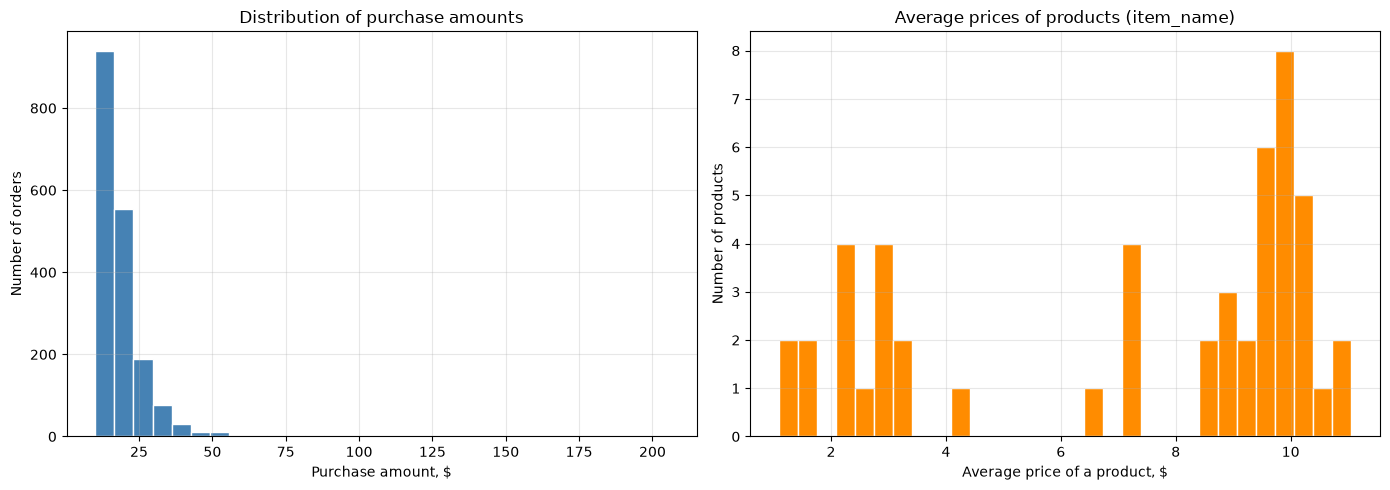

In [23]:
order_bills = df.groupby('order_id')['price'].sum()
avg_item_prices = df.groupby('item_name')['unit_price'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(order_bills, bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution of purchase amounts')
axes[0].set_xlabel('Purchase amount, $')
axes[0].set_ylabel('Number of orders')
axes[0].grid(True, alpha=0.3)

axes[1].hist(avg_item_prices, bins=30, color='darkorange', edgecolor='white')
axes[1].set_title('Average prices of products (item_name)')
axes[1].set_xlabel('Average price of a product, $')
axes[1].set_ylabel('Number of products')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


> **代码讲解**
>
> - `plt.subplots(1, 2, figsize=(14, 5))`：创建一张画布，切成一排两个坐标系 `axes[0]`、`axes[1]`。`1` 行 `2` 列。
> - `axes[0].hist(数据, bins=30)`：在左图画直方图，`bins=30` 表示把横轴切成 30 个区间，看每个区间落了多少个值。
> - `axes[1].hist(...)`：右图画商品平均单价。这里用的是 `unit_price` 的平均（每个商品一个值），所以横轴是"平均一个多少钱"。
> - `set_title` / `set_xlabel` / `set_ylabel` / `grid`：标题、轴标签、网格——就是上面说的"基本规矩"。
> - `plt.tight_layout()`：自动调整两张图的间距，别让标签互相压住。

**讲解与答案**

**左图：每张订单花多少钱。** 分布集中在 **10–30 美元**，右边拖着一条长尾巴——少数订单一次买很多（几十美元）。这和第 7 题的"平均 $18.81"对得上。

**右图：每种商品平均单价。** 大多数商品在 **2–12 美元**；右边的几根柱子就是最贵的沙拉碗（约 11 美元），和"答案速查"里第 5 题的结果一致。

**为什么用直方图？** 因为这两个问题问的都是"分布在哪里"，直方图一眼就能看出集中区间和长尾，用表格看不出来。


### 2. [1 分] 画出"每天的消费金额"随日期变化的图。


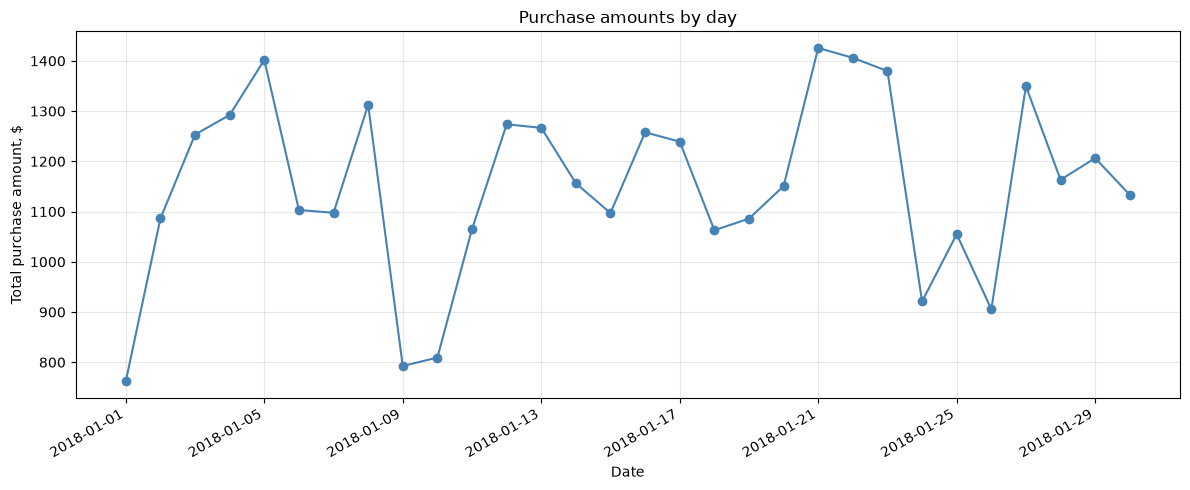

In [24]:
df['date'] = pd.to_datetime(df['date'])
daily = df.groupby('date')['price'].sum().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily.values, marker='o', color='steelblue')
plt.title('Purchase amounts by day')
plt.xlabel('Date')
plt.ylabel('Total purchase amount, $')
plt.grid(True, alpha=0.3)
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()


> **代码讲解**
>
> - `pd.to_datetime(df['date'])`：把字符串日期转成真正的时间类型（后面才能画好横轴）。
> - `df.groupby('date')['price'].sum().sort_index()`：按天分组、每天的钱加起来，再按日期排好序——这是折线图的横轴顺序。
> - `plt.plot(横坐标, 纵坐标, marker='o')`：画折线，每个数据点加个圆点，方便看清是哪天的值。
> - `plt.gcf().autofmt_xdate()`：日期横轴标签倾斜，避免挤在一起。

**讲解与答案**

横轴是 1 月的 31 天，纵轴是当天所有订单的总金额。因为日期是**随机分配**的，所以每天的金额忽高忽低、没有规律——这正是"假数据画真图"的样子。真实数据里你应该能看到周末高峰、节假日低谷之类的模式。

**为什么用折线图？** 因为问题是"金额怎么随天数变化"——时间有先后顺序，折线图天生适合表达趋势。


### 3. [1 分] 画柱状图：每张订单的平均金额按星期几分布。


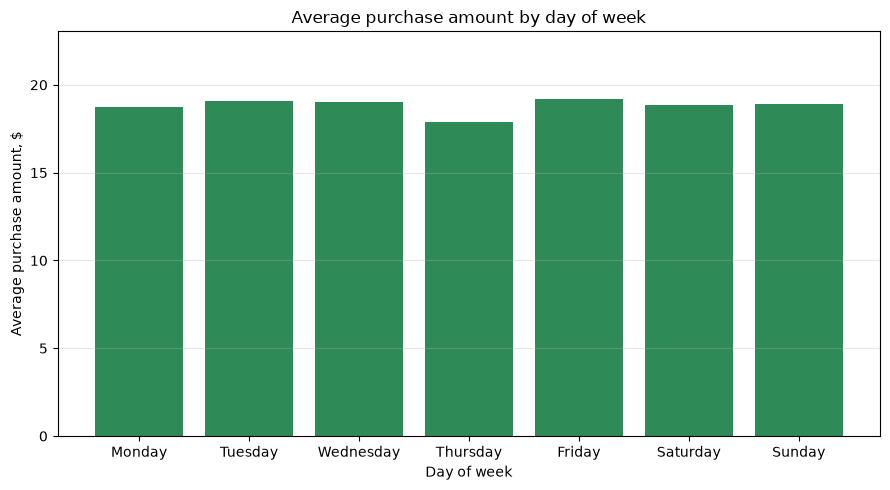

In [25]:
order_day = df.groupby('order_id').agg(bill=('price', 'sum'),
                                       date=('date', 'first'))
order_day['weekday'] = order_day['date'].dt.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday',
                 'Saturday', 'Sunday']
avg_by_weekday = order_day.groupby('weekday')['bill'].mean().reindex(weekday_order)

plt.figure(figsize=(9, 5))
plt.bar(avg_by_weekday.index, avg_by_weekday.values, color='seagreen')
plt.title('Average purchase amount by day of week')
plt.xlabel('Day of week')
plt.ylabel('Average purchase amount, $')
plt.ylim(0, avg_by_weekday.max() * 1.2)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


> **代码讲解**
>
> - `df.groupby('order_id').agg(bill=('price', 'sum'), date=('date', 'first'))`：先按订单汇总——每单总金额 + 这单的日期（同一单的日期都一样，取第一个就行）。
> - `order_day['date'].dt.day_name()`：从日期里取出"星期几"的英文名（Monday、Tuesday…）。
> - `weekday_order = [...]`：规定柱子的顺序。**这一步很重要**——直接分组的话 pandas 会按字母顺序排（Friday、Monday、Saturday…），读者看着别扭。
> - `.reindex(weekday_order)`：按我们指定的顺序重新排列。
> - `plt.bar(类别, 数值)`：画柱状图，横轴是星期几、纵轴是平均金额。

**讲解与答案**

7 根柱子高度几乎一样（都在 $18–19 附近）。原因还是那个"假日期"：**随机分配的日期和消费金额没有关系**。真实数据里通常能看到周末高一些。

**为什么用柱状图？** 因为"星期几"是**分类**变量（周一到周日，没有大小顺序），柱状图适合比较各分类的高矮；用折线图连起来反而会暗示"周一→周二有过渡"，不准确。


### 4. [1 分] 画散点图：一个商品花掉的钱 与 购买数量 的关系。


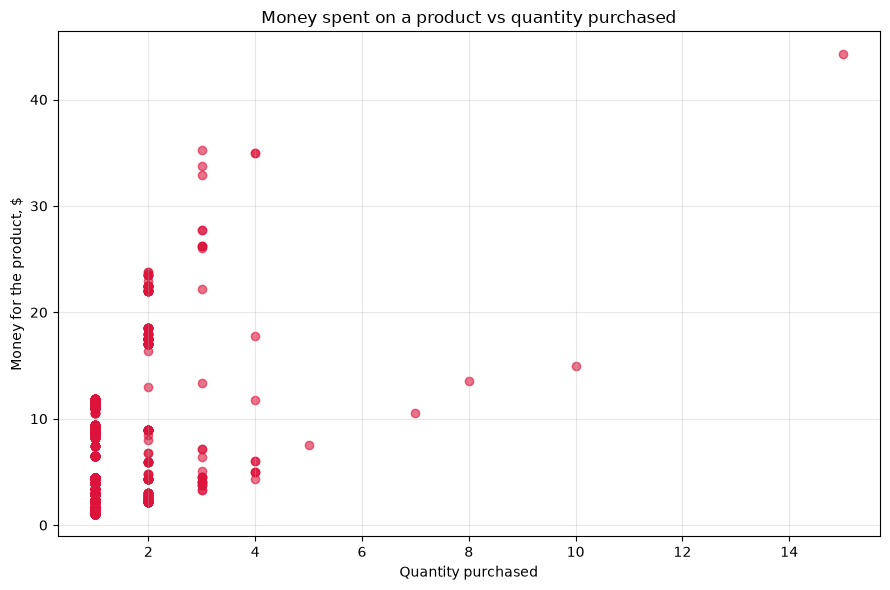

In [26]:
plt.figure(figsize=(9, 6))
plt.scatter(df['quantity'], df['price'], alpha=0.6, color='crimson')
plt.title('Money spent on a product vs quantity purchased')
plt.xlabel('Quantity purchased')
plt.ylabel('Money for the product, $')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


> **代码讲解**
>
> - `plt.scatter(横坐标, 纵坐标)`：画散点图，每个点是一行数据。
> - 这里横轴是 `quantity`（买了几件），纵轴是 `price`（这一行花了多少钱）。
> - `alpha=0.6`：半透明，点重叠时能看出颜色深浅（哪里更密）。
> - 坐标轴标签、标题、网格照例都加上。

**讲解与答案**

你会看到明显的"阶梯"：数量 1、2、3 时，钱成倍往上跳——因为 `price` 是**行总价 = 数量 × 单价**，而单价几乎不变。比如数据里 2 个 Chicken Bowl 是 $16.98（8.49 × 2）、3 罐饮料是 $3.75（1.25 × 3）。

**为什么用散点图？** 因为问题是"两个数值之间是什么关系"——散点图能同时看到每个点的位置和整体的趋势（这里就是一条条斜线）。这也正好印证第 5 题的坑：**`price` 不是单价**，比价格前要除以数量。


把这张图保存成 pdf（这样能保持矢量格式，放大不糊）。


In [27]:
# Save the current figure as a vector pdf
plt.savefig('money_vs_quantity.pdf', bbox_inches='tight')
print('Saved to money_vs_quantity.pdf')


Saved to money_vs_quantity.pdf


### 收尾

**提交。** 把这份 notebook（或你的版本）通过 EDUFPMI 提交。

**来源。** 本作业的解法只用了 pandas / matplotlib 官方文档（链接作业里已给出），没有参考其他开源代码。

### 自查清单

- [ ] 13 个表格题都打印了答案，且和"答案速查"对得上
- [ ] 4 张图都有标题、坐标轴标签、网格
- [ ] 散点图已保存成 PDF
- [ ] `random_matrix.csv` 已生成
- [ ] 评分栏写了你自己的估分（这份是 10 分参考解）


> **代码讲解**
>
> - `plt.savefig('文件名.pdf')`：把**当前这张图**存成文件。Jupyter 里执行完上一格，散点图还是"当前图"，所以这里直接保存就对了。
> - `bbox_inches='tight'`：自动裁掉多余白边。
> - 保存成 `.pdf` 是矢量格式，打印或放大都不失真；也可以存 `.png`（位图，放大糊）。